# Figure 5 -- the injected companion populations (`pop_diagnostics_1planet`, `pop_diagnostics_2planet`)

The prior distributions of the one-companion (left panel of the paper's figure) and two-companion
(right panel) populations, with the whole population (blue, *all*) and the high-SNR selection (rose)
overlaid on shared bins and normalized to densities, so each panel reads as *what the SNR floor
selects for* rather than as two sample sizes.

Everything is read from the injected truth tables in `catalog/data/`:

| table | what it is |
| --- | --- |
| `injected_solutions_1_companion.parquet` | every star, one injected companion |
| `injected_solutions_2_companion.parquet` | every star, two injected companions |
| `injected_solutions_{1,2}_companion_high_snr.parquet` | the systems whose companions **all** clear $\mathrm{SNR_{tot}} \ge 5$ |

The high-SNR tables are a row selection of the first two, made by the generator; the loader
re-derives the selection from the parent table and asserts the two agree, so the figure cannot
describe a stale cut. The figure code is `plot_population_diagnostics` from the generator's
`figures.py`, carried over verbatim apart from the loader.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The populations

`read_population` renames the truth-table schema onto the names the figure code uses
(`sma_1 -> sma`, `mass_st_msun -> mass_st`, `alpha_mas_k -> alpha_k_mas` for one-companion tables).

In [2]:
populations = {}
for n in (1, 2):
    populations[(n, False)] = pf.read_population(n)
    populations[(n, True)] = pf.read_population(n, high_snr=True)   # asserts == SNR_tot >= 5 cut

rows = []
for (n, hs), frame in populations.items():
    parent = populations[(n, False)]
    rows.append({"population": pf.POPULATION_LABELS[(n, hs)], "companions": n,
                 "selection": f"every SNR_tot >= {pf.C.HIGH_SNR_MIN:g}" if hs else "unbiased prior",
                 "systems": f"{len(frame):,}",
                 "of parent": f"{100 * len(frame) / len(parent):.2f}%" if hs else ""})
pd.DataFrame(rows).set_index("population")

,companions,selection,systems,of parent
population,,,,
one-companion,1,unbiased prior,"5,040,328",
"one-companion, high-SNR",1,every SNR_tot >= 5,"436,883",8.67%
two-companions,2,unbiased prior,"5,040,328",
"two-companions, high-SNR",2,every SNR_tot >= 5,"25,946",0.51%


### Numbers for the text

The sample sizes, the near-resonant counts of the two-companion populations, and the coplanar
fraction -- read off the tables rather than typed in.

In [3]:
N_STARS = len(populations[(1, False)])
assert N_STARS == len(populations[(2, False)])
print(f"stars simulated in every population : {N_STARS:,}   ({3 * N_STARS:,} systems in the catalog)")
for n in (1, 2):
    hs = populations[(n, True)]
    print(f"{n}-companion high-SNR (every SNR_tot >= {pf.C.HIGH_SNR_MIN:g}) : {len(hs):,}  "
          f"({100 * len(hs) / N_STARS:.2f}% of the parent sample)")

two, two_hs = populations[(2, False)], populations[(2, True)]
for label, frame in (("two-companions", two), ("two-companions, high-SNR", two_hs)):
    n21, n32 = int(frame["near_2_1"].sum()), int(frame["near_3_2"].sum())
    nres = int(frame["near_resonance"].sum())
    print(f"{label:26s}: {nres:,} near-resonant ({100 * nres / len(frame):.2f}%): "
          f"{n21:,} near 2:1, {n32:,} near 3:2;  coplanar {100 * frame['coplanar'].mean():.1f}%")

one = populations[(1, False)]
print(f"\nperiod range injected: {one['period'].min():.4f} - {one['period'].max():.0f} yr; "
      f"a: {one['sma'].min():.4f} - {one['sma'].max():.1f} au; "
      f"M_p: {one['mass_pl'].min():.2e} - {one['mass_pl'].max():.1f} M_Jup")

stars simulated in every population : 5,040,328   (15,120,984 systems in the catalog)
1-companion high-SNR (every SNR_tot >= 5) : 436,883  (8.67% of the parent sample)
2-companion high-SNR (every SNR_tot >= 5) : 25,946  (0.51% of the parent sample)
two-companions            : 16,615 near-resonant (0.33%): 12,388 near 2:1, 4,227 near 3:2;  coplanar 50.0%
two-companions, high-SNR  : 272 near-resonant (1.05%): 208 near 2:1, 64 near 3:2;  coplanar 50.7%

period range injected: 0.0030 - 3168 yr; a: 0.0300 - 100.0 au; M_p: 3.37e-04 - 80.0 M_Jup


## 2. The figure

Two panel grids, one per companion count. One companion: semimajor axis, stellar mass, companion
mass, period (with the DR4 baseline marked), eccentricity, inclination. Two companions: both
semimajor axes, the period ratio (with the 2:1 and 3:2 commensurabilities marked, where the
near-resonant systems pile up), both masses, the inner inclination, both eccentricities, and the
mutual inclination of the non-coplanar half.

In [4]:
from matplotlib.patches import Patch


def plot_population_diagnostics(n_companions, random, high_snr, stem, paper=False):
    """Overlaid prior distributions for the whole population and the high-SNR selection."""
    random_color, snr_color = pf.RANDOM_COLOR, pf.HIGH_SNR_COLOR

    def overlay(ax, left, right, bins=60):
        left, right = np.asarray(left), np.asarray(right)
        finite = np.concatenate([left[np.isfinite(left)], right[np.isfinite(right)]])
        edges = np.histogram_bin_edges(finite, bins=bins)
        for values, color in [(left, random_color), (right, snr_color)]:
            ax.hist(values, bins=edges, density=True, histtype="stepfilled",
                    color=color, edgecolor=color, linewidth=1.3, alpha=0.25)

    def style(axes):
        for ax in np.asarray(axes).flat:
            ax.grid(axis="y", alpha=0.18, linewidth=0.7)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.tick_params(width=1.1, length=5)
            ax.margins(x=0.02)

    # "all", not "random": both curves come from the same unbiased prior; what separates
    # them is that one is everything and the other is a selection over it.
    handles = [
        Patch(facecolor=random_color, edgecolor=random_color, alpha=0.40, linewidth=1.3,
              label=rf"all ($N={pf.tex_num(len(random))}$)"),
        Patch(facecolor=snr_color, edgecolor=snr_color, alpha=0.40, linewidth=1.3,
              label=rf"high-SNR ($N={pf.tex_num(len(high_snr))}$)"),
    ]
    cos_bins = np.linspace(-1, 1, 50)

    with plt.rc_context({"axes.titlesize": 40, "axes.labelsize": 40,
                         "xtick.labelsize": 34, "ytick.labelsize": 34,
                         "legend.fontsize": 36, "axes.linewidth": 1.2}):
        if n_companions == 2:
            fig, axes = plt.subplots(3, 3, figsize=(15, 13.5))

            overlay(axes[0, 0], np.log10(random["sma_1"]), np.log10(high_snr["sma_1"]))
            axes[0, 0].set(xlabel=r"$\log_{10}(a_1)$ [au]", title=r"inner semimajor axis")
            overlay(axes[0, 1], np.log10(random["sma_2"]), np.log10(high_snr["sma_2"]))
            axes[0, 1].set(xlabel=r"$\log_{10}(a_2)$ [au]", title=r"outer semimajor axis")

            overlay(axes[0, 2], np.log10(random["P_ratio"]), np.log10(high_snr["P_ratio"]))
            axes[0, 2].set(xlabel=r"$\log_{10}(P_2/P_1)$", title=r"period ratio")
            axes[0, 2].set_ylim(top=axes[0, 2].get_ylim()[1] * 1.15)
            for j, sign in zip(pf.C.RESONANCE_ORDERS, (+1, -1)):   # the first-order MMRs
                x = np.log10((j + 1) / j)
                axes[0, 2].axvline(x, color="0.30", ls="--", lw=1.5)
                axes[0, 2].annotate(rf"{j + 1}:{j}", xy=(x, 0.62),
                                    xycoords=("data", "axes fraction"),
                                    xytext=(7 * sign, 0), textcoords="offset points",
                                    rotation=90, rotation_mode="anchor",
                                    ha="left" if sign > 0 else "right", va="center",
                                    fontsize=26, color="0.30")

            overlay(axes[1, 0], np.log10(random["mass_pl_1"]), np.log10(high_snr["mass_pl_1"]))
            axes[1, 0].set(xlabel=r"$\log_{10}(M_{\mathrm{p},1})$ [$M_{\mathrm{Jup}}$]",
                           title=r"inner planet mass")
            overlay(axes[1, 1], np.log10(random["mass_pl_2"]), np.log10(high_snr["mass_pl_2"]))
            axes[1, 1].set(xlabel=r"$\log_{10}(M_{\mathrm{p},2})$ [$M_{\mathrm{Jup}}$]",
                           title=r"outer planet mass")
            overlay(axes[1, 2], np.cos(np.radians(random["inc_1"])),
                    np.cos(np.radians(high_snr["inc_1"])), bins=cos_bins)
            axes[1, 2].set(xlabel=r"$\cos(i_1)$", title=r"inclination")

            overlay(axes[2, 0], random["ecc_1"], high_snr["ecc_1"], bins=50)
            axes[2, 0].set(xlabel=r"$e_1$", title=r"inner eccentricity")
            overlay(axes[2, 1], random["ecc_2"], high_snr["ecc_2"], bins=50)
            axes[2, 1].set(xlabel=r"$e_2$", title=r"outer eccentricity")

            def mutual_inclination(frame):
                """cos i_mut = cos i1 cos i2 + sin i1 sin i2 cos(Omega1 - Omega2)."""
                i1 = np.radians(frame["inc_1"].to_numpy())
                i2 = np.radians(frame["inc_2"].to_numpy())
                dnode = np.radians(frame["Omega_1"].to_numpy() - frame["Omega_2"].to_numpy())
                cos_mutual = np.cos(i1) * np.cos(i2) + np.sin(i1) * np.sin(i2) * np.cos(dnode)
                return np.degrees(np.arccos(np.clip(cos_mutual, -1.0, 1.0)))

            # coplanar systems sit at i_mut = 0 by construction and would swamp the panel
            overlay(axes[2, 2],
                    mutual_inclination(random[~random["coplanar"].astype(bool)]),
                    mutual_inclination(high_snr[~high_snr["coplanar"].astype(bool)]))
            axes[2, 2].set(xlabel=r"$i_{\mathrm{mut}}$ [deg]", title=r"mutual inclination")
            axes[2, 2].set_ylim(top=axes[2, 2].get_ylim()[1] * 1.22)
            axes[2, 2].text(0.5, 0.95, r"non-coplanar half", transform=axes[2, 2].transAxes,
                            ha="center", va="top", fontsize=27, color="0.25")

            title = r"\texttt{epochalypse} injected two-companion systems"
            rect_top, sup_y = 0.915, 0.99
        else:
            fig, axes = plt.subplots(2, 3, figsize=(15, 10.5))

            overlay(axes[0, 0], np.log10(random["sma"]), np.log10(high_snr["sma"]))
            axes[0, 0].set(xlabel=r"$\log_{10}(a)$ [au]", title=r"semimajor axis")
            overlay(axes[0, 1], np.log10(random["mass_st"]), np.log10(high_snr["mass_st"]))
            axes[0, 1].set(xlabel=r"$\log_{10}(M_\star)$ [$M_\odot$]", title=r"stellar mass")
            overlay(axes[0, 2], np.log10(random["mass_pl"]), np.log10(high_snr["mass_pl"]))
            axes[0, 2].set(xlabel=r"$\log_{10}(M_{\mathrm{p}})$ [$M_{\mathrm{Jup}}$]",
                           title=r"planet mass")

            overlay(axes[1, 0], np.log10(random["period"]), np.log10(high_snr["period"]))
            axes[1, 0].set(xlabel=r"$\log_{10}(P)$ [yr]", title=r"orbital period")
            axes[1, 0].axvline(np.log10(pf.BASELINE), color="0.25", ls=":", lw=3)
            axes[1, 0].annotate(r"DR4 baseline", xy=(np.log10(pf.BASELINE) - 0.05, 0.04),
                                xycoords=("data", "axes fraction"),
                                xytext=(6, 0), textcoords="offset points",
                                rotation=90, rotation_mode="anchor",
                                ha="left", va="bottom", fontsize=24, color="0.25")

            overlay(axes[1, 1], random["ecc"], high_snr["ecc"], bins=50)
            axes[1, 1].set(xlabel=r"$e$", title=r"eccentricity")
            overlay(axes[1, 2], np.cos(np.radians(random["inc"])),
                    np.cos(np.radians(high_snr["inc"])), bins=cos_bins)
            axes[1, 2].set(xlabel=r"$\cos(i)$", title=r"inclination")

            title = r"\texttt{epochalypse} injected one-companion systems"
            rect_top, sup_y = 0.875, 0.985

        style(axes)
        for ax in axes[:, 0]:
            ax.set_ylabel("density")

        fig.tight_layout(rect=[0, 0, 1, rect_top])
        suptitle = fig.suptitle(title, fontsize=50, y=sup_y)

        # centre the shared legend in the gap between the panel titles and the suptitle
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        inverse = fig.transFigure.inverted()
        title_top = max(inverse.transform((0, ax.title.get_window_extent(renderer).ymax))[1]
                        for ax in axes[0, :])
        sup_bottom = inverse.transform((0, suptitle.get_window_extent(renderer).ymin))[1]
        fig.legend(handles=handles, loc="center", ncol=2,
                   bbox_to_anchor=(0.5, 0.5 * (title_top + sup_bottom)),
                   frameon=False, fontsize=36, handlelength=1.7, handleheight=1.2,
                   columnspacing=2.4)

    written = pf.save(fig, stem, dpi=300, paper=paper)
    plt.close(fig)
    return written

## 3. The paper figure: panels (a) and (b)

`pop_diagnostics_1planet.pdf` (Fig. 5a) and `pop_diagnostics_2planet.pdf` (Fig. 5b).

  wrote analysis/paper_figures/pop_diagnostics_1planet.pdf, analysis/paper_figures/pop_diagnostics_1planet.png


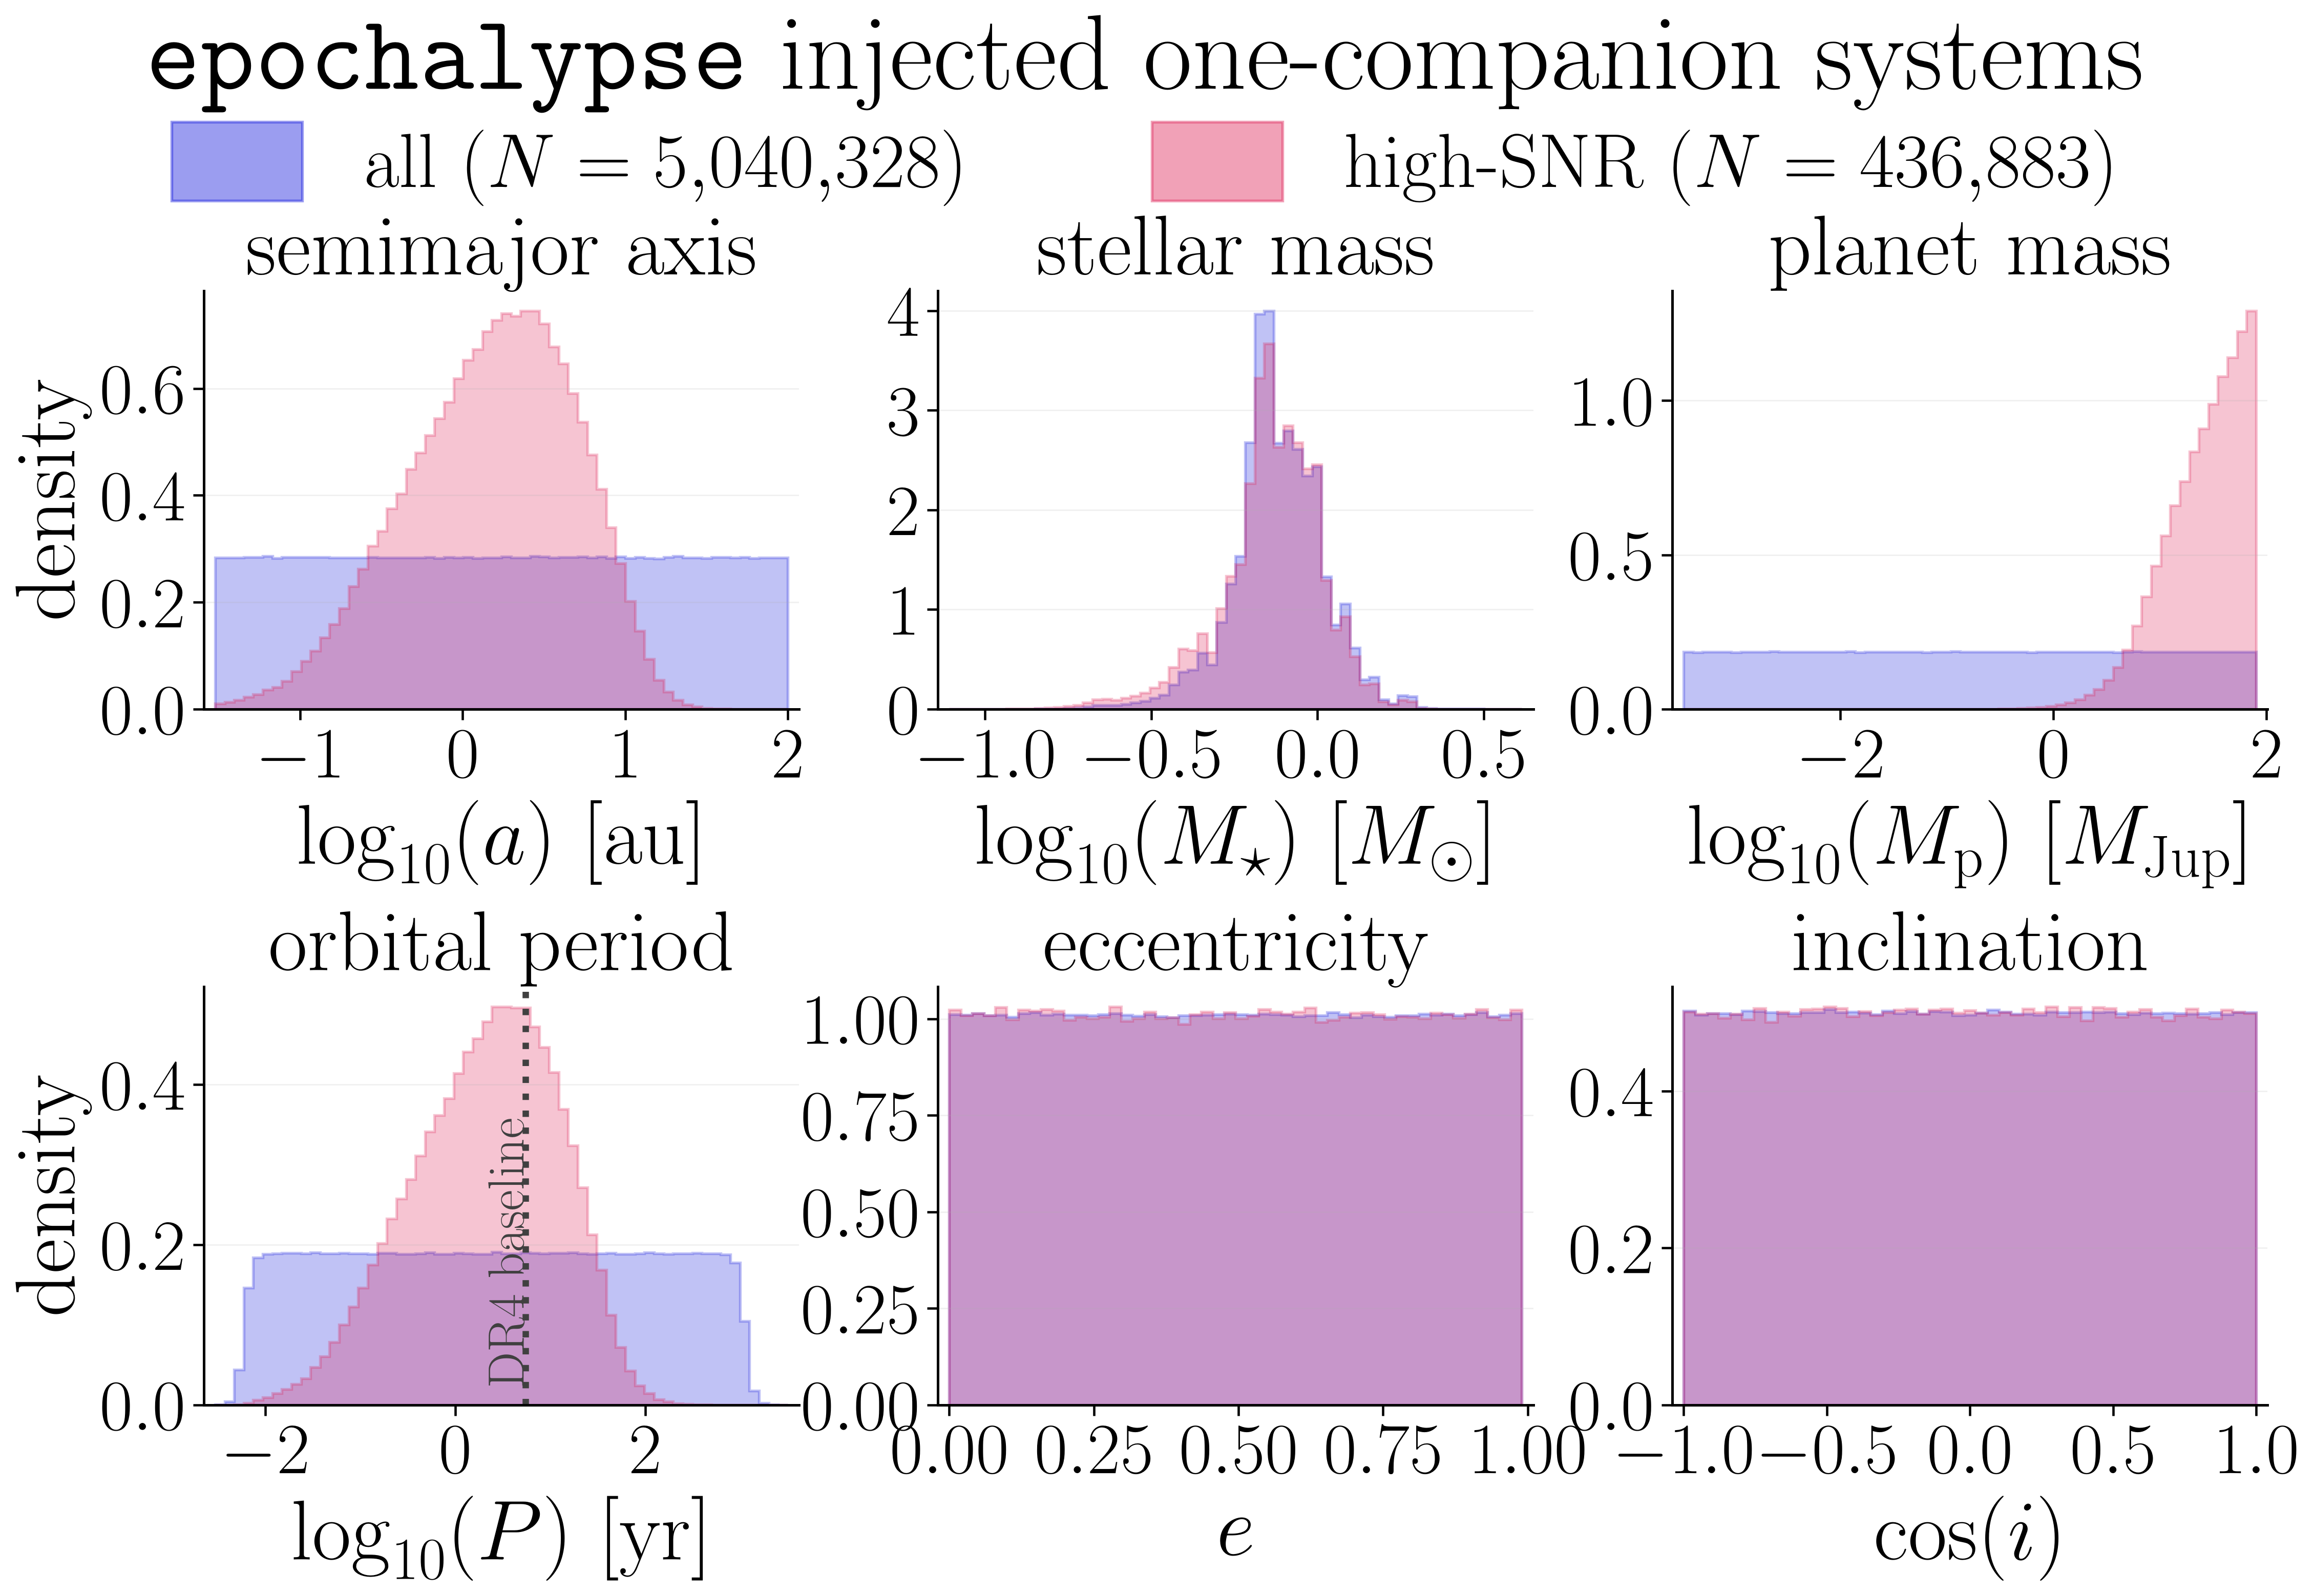

  wrote analysis/paper_figures/pop_diagnostics_2planet.pdf, analysis/paper_figures/pop_diagnostics_2planet.png


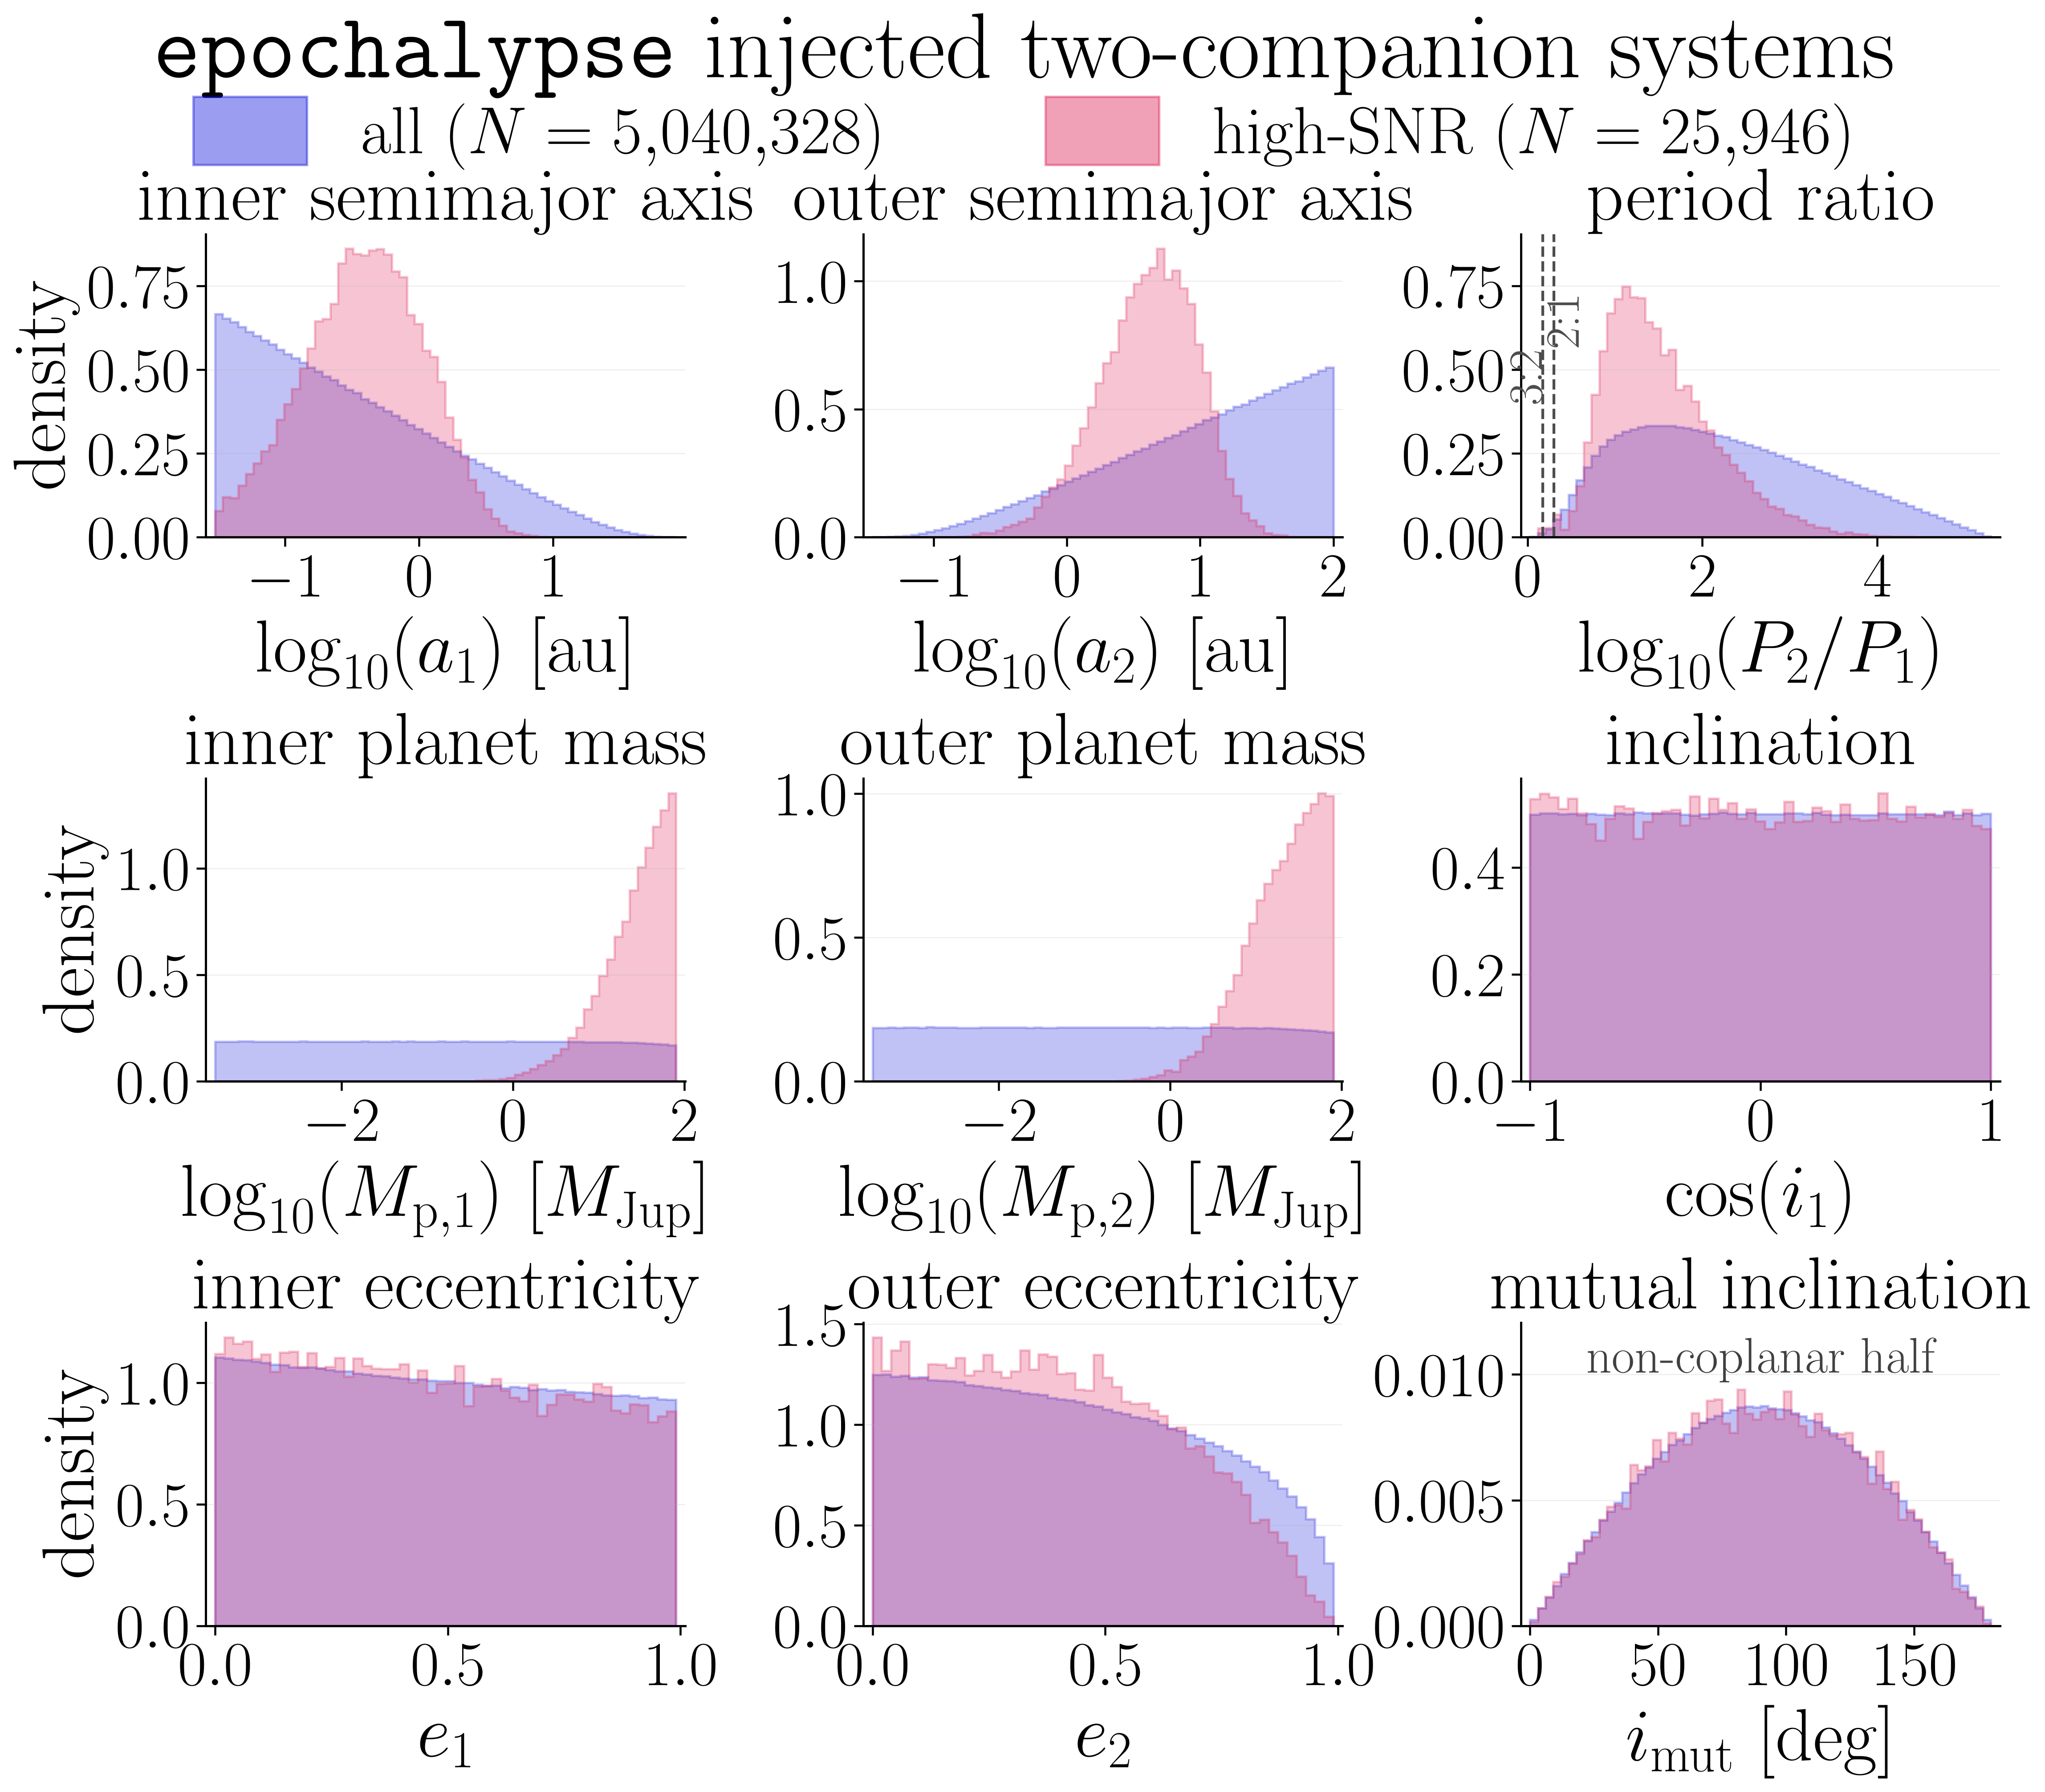

In [5]:
for n in (1, 2):
    plot_population_diagnostics(n, populations[(n, False)], populations[(n, True)],
                                f"pop_diagnostics_{n}planet", paper=True)
    display(Image(filename=str(pf.PAPER_FIG_DIR / f"pop_diagnostics_{n}planet.png"), width=1000))